In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate time series representing a loading duration
time = np.linspace(0, 100, 1000)  # 1000 points representing simulated time

# Define multiple signal components representing variable amplitude loading
low_freq_trend = 10 * np.sin(2 * np.pi * 0.05 * time)
mid_freq_fluctuation = 60 * np.sin(2 * np.pi * 0.2 * time) * np.cos(2 * np.pi * 0.02 * time)
high_freq_noise = np.random.normal(loc=0, scale=15, size=len(time))

# Combine components to form the final stress history (in MPa)
stress_history = low_freq_trend + mid_freq_fluctuation + high_freq_noise

<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_9873/686821050.py:13: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Fatigue life, $\mathrm{N_f}$")
/tmp/ipykernel_9873/686821050.py:14: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel("Stress amplitude, $\sigma_\mathrm{a}$ (MPa)")


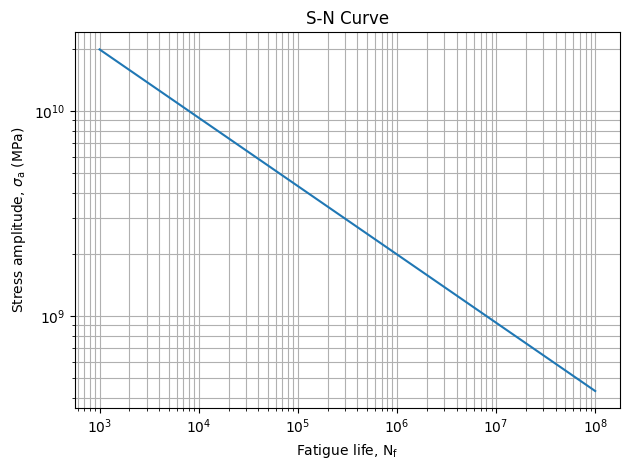

In [ ]:
# Define typical structural steel S-N curve parameters
m = 3.0           # Fatigue exponent
C = 2.0e11        # Material constant (MPa scale)

# Stress cycles from 10^3 to 10^8
life = np.logspace(3, 8, 500)

# Correct Basquin relation: S = (C / N)**(1/m)
stress_amplitude = (C / life) ** (1 / m)

plt.figure(figsize=(6, 4))
plt.loglog(life, stress_amplitude, label=r'$N_f \cdot S^3 = 2 \times 10^{11}$')
plt.xlabel(r"Fatigue life, $N_f$")
plt.ylabel(r"Stress amplitude, $\sigma_a$ (MPa)")
plt.title("S-N Curve (Corrected Basquin Relation)")
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

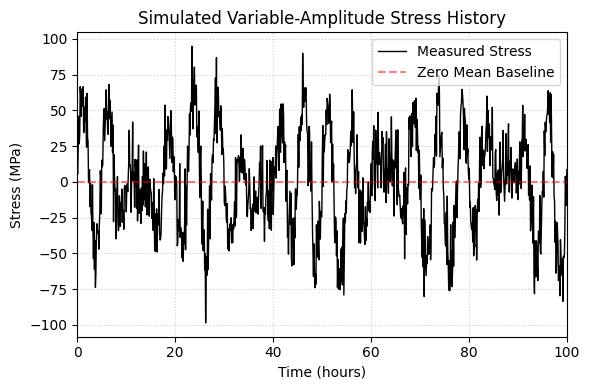

In [ ]:
# Plot the generated stress history
plt.figure(figsize=(6, 4))
plt.plot(time, stress_history, color='k', linewidth=1.0, label='Measured Stress')
plt.axhline(0, color='red', linestyle='--', alpha=0.5, label='Zero Mean Baseline')
plt.title('Simulated Variable-Amplitude Stress History')
plt.xlabel('Time (hours)')
plt.ylabel('Stress (MPa)')
plt.xlim([0.00, 100.00])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def hysteresis_filter(signal, threshold):
    ## Removes small fluctuations smaller than the threshold
    if len(signal) == 0:
        return np.array([])
    filtered = [signal[0]]
    for value in signal[1:]:
        if abs(value - filtered[-1]) >= threshold:
            filtered.append(value)
    return np.array(filtered)

In [ ]:
def peak_valley_filter(signal):
    ## Keeps only local maxima and minima, removing intermediate points
    if len(signal) < 3:
        return np.array(signal)
    filtered = [signal[0]]
    for i in range(1, len(signal) - 1):
        prev_val, curr_val, next_val = signal[i-1], signal[i], signal[i+1]
        # Check if the current point is a local peak or valley
        if (curr_val > prev_val and curr_val > next_val) or (curr_val < prev_val and curr_val < next_val):
            filtered.append(curr_val)
    filtered.append(signal[-1])
    return np.array(filtered)

In [ ]:
def cycle_counting(extrema):
    ## Custom simplified cycle counting (One-Range Counting)
    ## Identifies cycles based on matching successive ranges
    points = list(extrema)
    cycles = []
    i = 0
    while i < len(points) - 2:
        # Calculate successive ranges
        range1 = abs(points[i+1] - points[i])
        range2 = abs(points[i+2] - points[i+1])
        if range2 >= range1:
            # Record a cycle
            mean = (points[i] + points[i+1]) / 2.0
            cycles.append((range1, mean))
            # Remove the pair that formed the cycle
            points.pop(i+1)
            points.pop(i)
            # Reset pointer to evaluate the context again
            i = max(0, i - 1)
        else:
            i += 1
    return cycles

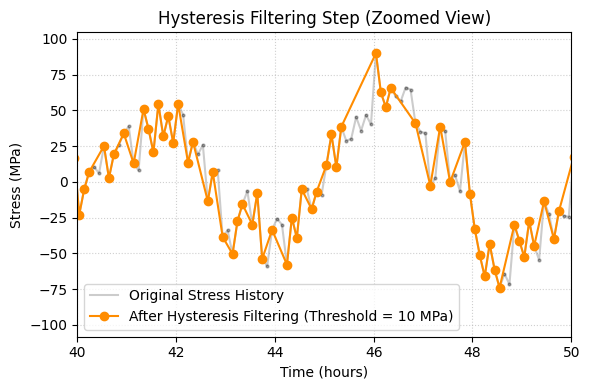

In [ ]:
# Apply Step 1: Hysteresis Filtering (Threshold = 10 MPa)
filtered_hyst = hysteresis_filter(stress_history, threshold=10.0)

# Reconstruct times for the hysteresis filtered points
hyst_indices = []
curr_idx = 0
for val in filtered_hyst:
    for idx in range(curr_idx, len(stress_history)):
        if np.isclose(stress_history[idx], val):
            hyst_indices.append(idx)
            curr_idx = idx + 1
            break
hyst_times = time[hyst_indices]

plt.figure(figsize=(6, 4))
plt.plot(time, stress_history, color='gray', linestyle='-', alpha=0.4, label='Original Stress History')
plt.plot(time, stress_history, 'k.', markersize=4, alpha=0.3)
plt.plot(hyst_times, filtered_hyst, color='darkorange', linestyle='-', marker='o', markersize=6, label='After Hysteresis Filtering (Threshold = 10 MPa)')

plt.title('Hysteresis Filtering Step (Zoomed View)')
plt.xlabel('Time (hours)')
plt.ylabel('Stress (MPa)')
plt.xlim([40.0, 50.0])  # Zooming into a specific, narrow range
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

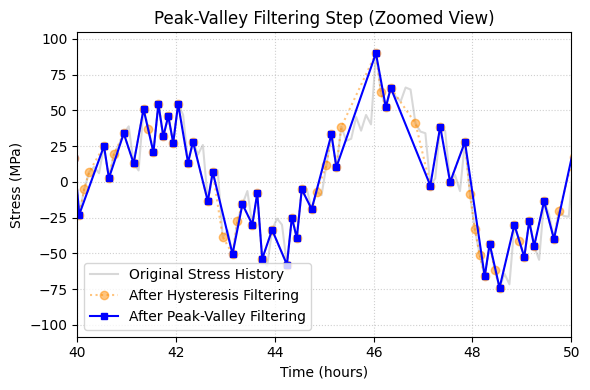

In [ ]:
# Apply Step 2: Peak-Valley Filtering
filtered_pv = peak_valley_filter(filtered_hyst)

# Reconstruct original time indices for peak-valley filtered points
pv_indices = []
curr_idx = 0
for val in filtered_pv:
    for idx in range(curr_idx, len(stress_history)):
        if np.isclose(stress_history[idx], val):
            pv_indices.append(idx)
            curr_idx = idx + 1
            break
pv_times = time[pv_indices]

# Plot the comparison
plt.figure(figsize=(6, 4))
plt.plot(time, stress_history, color='gray', linestyle='-', alpha=0.3, label='Original Stress History')
plt.plot(hyst_times, filtered_hyst, color='darkorange', linestyle=':', marker='o', alpha=0.5, label='After Hysteresis Filtering')
plt.plot(pv_times, filtered_pv, color='blue', linestyle='-', marker='s', markersize=5, label='After Peak-Valley Filtering')

plt.title('Peak-Valley Filtering Step (Zoomed View)')
plt.xlabel('Time (hours)')
plt.ylabel('Stress (MPa)')
plt.xlim([40.0, 50.0])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Apply Step 3: Cycle Counting
counted_cycles = cycle_counting(filtered_pv)

# Print summary and show first few cycles
print(f"Original stress points: {len(stress_history)}")
print(f"After Hysteresis filtering: {len(filtered_hyst)}")
print(f"After Peak-Valley filtering: {len(filtered_pv)}")
print(f"Total custom cycles counted: {len(counted_cycles)}\n")

print("Sample of Custom Cycles (Range, Mean):")
for idx, (s_range, s_mean) in enumerate(counted_cycles[:10]):
    print(f"Cycle {idx+1:02d}: Range = {s_range:6.2f} MPa, Mean = {s_mean:6.2f} MPa")

Original stress points: 1000
After Hysteresis filtering: 643
After Peak-Valley filtering: 460
Total custom cycles counted: 190

Sample of Custom Cycles (Range, Mean):
Cycle 01: Range =  19.24 MPa, Mean =  36.26 MPa
Cycle 02: Range =  12.12 MPa, Mean =  58.84 MPa
Cycle 03: Range =  20.64 MPa, Mean =  56.20 MPa
Cycle 04: Range =  17.77 MPa, Mean =  43.24 MPa
Cycle 05: Range =  37.66 MPa, Mean =  43.08 MPa
Cycle 06: Range =  16.16 MPa, Mean =  -9.19 MPa
Cycle 07: Range =  31.80 MPa, Mean = -17.99 MPa
Cycle 08: Range =  25.34 MPa, Mean = -41.06 MPa
Cycle 09: Range =  20.24 MPa, Mean = -50.97 MPa
Cycle 10: Range =  17.77 MPa, Mean = -38.20 MPa


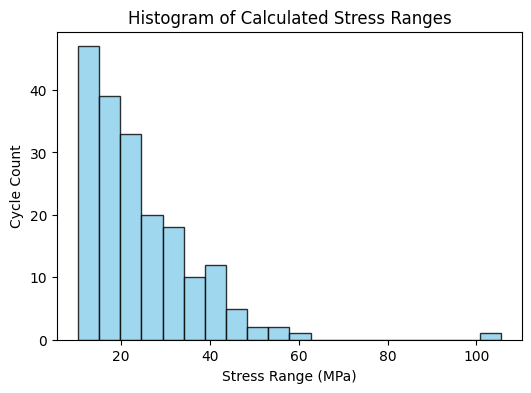

In [ ]:
# Extract only the stress ranges from the custom counted cycles
stress_ranges = [cycle[0] for cycle in counted_cycles]

# Plot the histogram
plt.figure(figsize=(6, 4))
plt.hist(stress_ranges, bins=20, color='skyblue', edgecolor='black', alpha=0.8)
plt.title('Histogram of Calculated Stress Ranges')
plt.xlabel('Stress Range (MPa)')
plt.ylabel('Cycle Count')
plt.show()

In [ ]:
# We need to trace each counted cycle back to its original time index, time point, and stress value
# To do this, we re-run a trace-enabled cycle counting on the filtered_pv
points_list = list(filtered_pv)

# Find the original stress_history indices for each filtered_pv point
filtered_pv_orig_indices = []
curr_idx = 0
for val in filtered_pv:
    for idx in range(curr_idx, len(stress_history)):
        if np.isclose(stress_history[idx], val):
            filtered_pv_orig_indices.append(idx)
            curr_idx = idx + 1
            break

# Store tracking info: (value, original_index, original_time)
indexed_points = [(filtered_pv[i], filtered_pv_orig_indices[i], time[filtered_pv_orig_indices[i]]) for i in range(len(filtered_pv))]

results = []
cycle_id = 1

while len(indexed_points) >= 3:
    i = 0
    cycle_found = False
    while i < len(indexed_points) - 2:
        range1 = abs(indexed_points[i+1][0] - indexed_points[i][0])
        range2 = abs(indexed_points[i+2][0] - indexed_points[i+1][0])

        if range2 >= range1:
            # A cycle is identified between index i and i+1
            p1 = indexed_points[i]
            p2 = indexed_points[i+1]

            # Identify which point is the max and which is the min
            if p1[0] >= p2[0]:
                max_pt, min_pt = p1, p2
            else:
                max_pt, min_pt = p2, p1

            s_range = range1
            N_f = C / (s_range ** m) if s_range > 0 else float('inf')
            damage = 1.0 / N_f if N_f != float('inf') else 0.0

            results.append({
                "Cycle ID": cycle_id,
                "Min Stress Index": min_pt[1],
                "Min Time Point (hr)": round(min_pt[2], 4),
                "Min Stress (MPa)": round(min_pt[0], 2),
                "Max Stress Index": max_pt[1],
                "Max Time Point (hr)": round(max_pt[2], 4),
                "Max Stress (MPa)": round(max_pt[0], 2),
                "Stress Range (MPa)": round(s_range, 2),
                "Allowable Cycles (N_f)": int(N_f) if N_f != float('inf') else "Infinite",
                "Damage Contribution (D_i)": damage
            })

            cycle_id += 1
            indexed_points.pop(i+1)
            indexed_points.pop(i)
            cycle_found = True
            break
        else:
            i += 1
    if not cycle_found:
        break

# Convert to DataFrame
damage_df = pd.DataFrame(results)

# Display the top 15 most damaging cycles in a table
display(damage_df.sort_values(by="Damage Contribution (D_i)", ascending=False).head(15))

,Cycle ID,Min Stress Index,Min Time Point (hr),Min Stress (MPa),Max Stress Index,Max Time Point (hr),Max Stress (MPa),Stress Range (MPa),Allowable Cycles (N_f),Damage Contribution (D_i)
62,63,37,3.7037,-73.74,234,23.4234,94.90,168.64,41701,0.000024
226,227,708,70.8709,-80.23,738,73.8739,74.28,154.51,54215,0.000018
107,108,442,44.2442,-57.87,284,28.4284,86.86,144.73,65969,0.000015
164,165,544,54.4545,-79.12,561,56.1562,64.41,143.53,67645,0.000015
223,224,933,93.3934,-78.22,961,96.1962,63.79,142.01,69835,0.000014
210,211,760,76.0761,-76.11,785,78.5786,64.68,140.79,71673,0.000014
125,126,485,48.5485,-74.05,515,51.5516,61.33,135.39,80589,0.000012
53,54,216,21.6216,-55.53,59,5.9059,64.38,119.92,115982,0.000009
209,210,815,81.5816,-54.66,836,83.6837,60.00,114.67,132656,0.000008
162,163,668,66.8669,-53.79,691,69.1692,58.53,112.32,141152,0.000007


In [ ]:
# Calculate and display cumulative damage
total_damage = damage_df["Damage Contribution (D_i)"].sum()
print(f"Total Cumulative Fatigue Damage (D): {total_damage:.3e}")
if total_damage > 0:
    estimated_lifetime_hours = 1.0 / total_damage
    print(f"Estimated fatigue life under this stress profile: {estimated_lifetime_hours:,.0f} hours")

Total Cumulative Fatigue Damage (D): 1.907e-04
Estimated fatigue life under this stress profile: 524,306 hours
